In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# 디렉토리 경로
dir1 = 'dataset/21-30_white'
dir2 = 'dataset/21-30_white_masked'

# 두 디렉토리의 공통 파일명 찾기
files1 = set(os.listdir(dir1))
files2_raw = set(os.listdir(dir2))

# dir2 파일에서 "_surgical" 제거해서 기본 파일명 추출
files2 = set(f.replace('_surgical.png', '.png') for f in files2_raw)

common_files = sorted(list(files1 & files2))

print(f"공통 파일 수: {len(common_files)}")
print(f"첫 10개 파일: {common_files[:10]}")

공통 파일 수: 100
첫 10개 파일: ['0008-Female-27.png', '0009-Female-21.png', '0015-Female-25.png', '0018-Female-29.png', '0019-Female-30.png', '0020-Female-22.png', '0022-Female-27.png', '0023-Female-26.png', '0027-Female-26.png', '0033-Female-27.png']


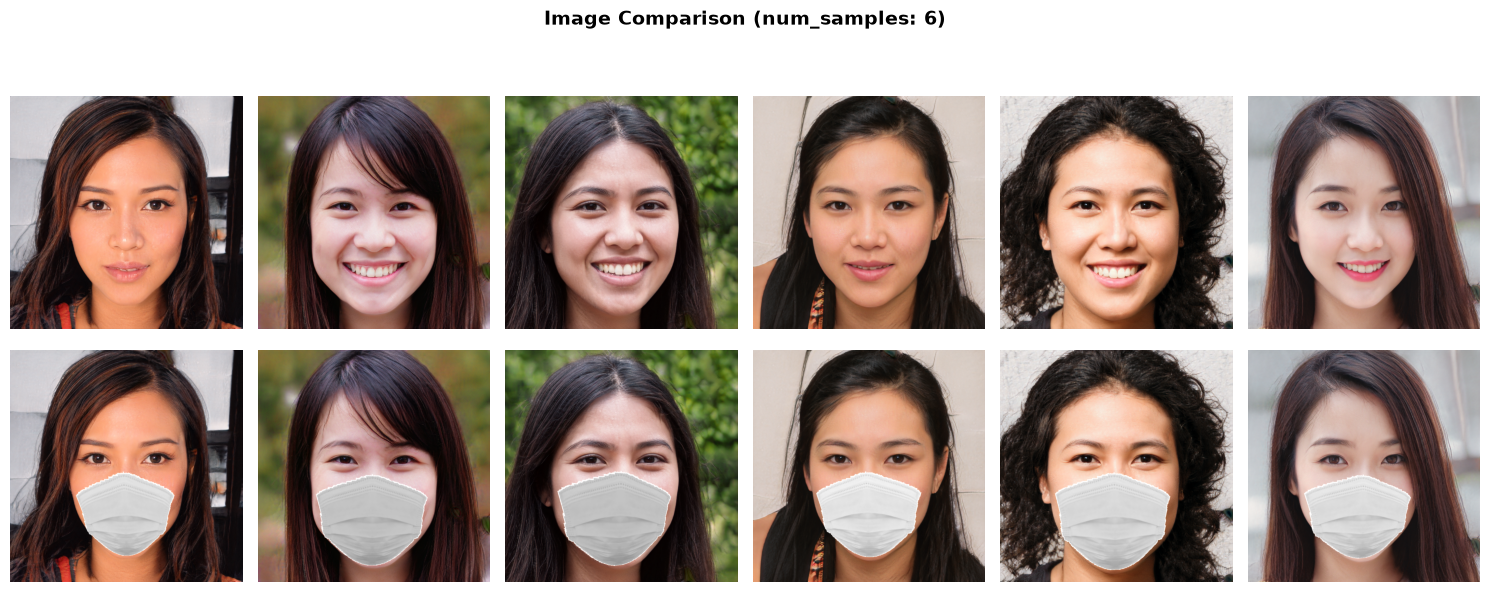


Selected files:
  - 0008-Female-27.png
  - 0009-Female-21.png
  - 0015-Female-25.png
  - 0018-Female-29.png
  - 0019-Female-30.png
  - 0020-Female-22.png


In [10]:
# 처음 6개 파일 선택
num_samples = 6
selected_files = common_files[:num_samples]

# 2 * num_samples 그리드 (위: 21-30_white, 아래: 21-30_white_masked)
fig, axes = plt.subplots(2, num_samples, figsize=(15, 6))

for idx, filename in enumerate(selected_files):
    # 위: dataset/21-30_white
    img1 = Image.open(os.path.join(dir1, filename))
    axes[0, idx].imshow(img1)
    axes[0, idx].axis('off')
    
    # 아래: dataset/21-30_white_masked (_surgical 버전)
    masked_filename = filename.replace('.png', '_surgical.png')
    img2 = Image.open(os.path.join(dir2, masked_filename))
    axes[1, idx].imshow(img2)
    axes[1, idx].axis('off')

# y축 레이블 추가
axes[0, 0].set_ylabel('21-30_white', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('21-30_white_masked', fontsize=12, fontweight='bold')

plt.suptitle(f'Image Comparison (num_samples: {num_samples})', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\nSelected files:")
for f in selected_files:
    print(f"  - {f}")

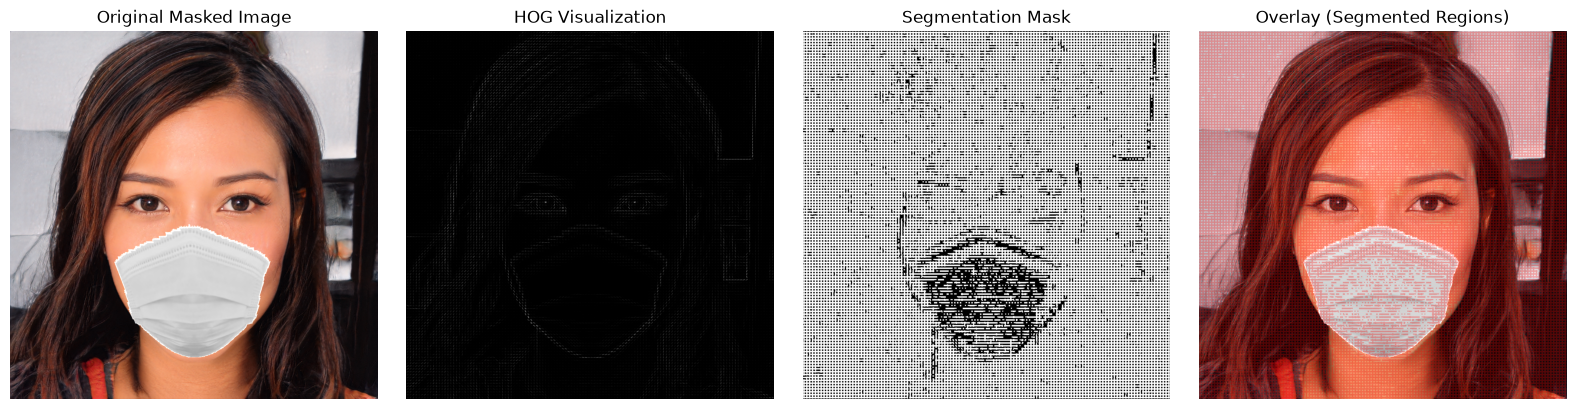

HOG 특성 차원: (580644,)
세그먼테이션 마스크 크기: (1024, 1024)
세그먼테이션된 영역 비율: 69.40%


In [3]:
from skimage.feature import hog
from scipy import ndimage

def segment_with_hog(img_array, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):
    """
    HOG를 사용해 마스크 영역을 segmentation
    
    Parameters:
    - img_array: PIL Image 또는 numpy array
    - pixels_per_cell: HOG 셀 크기
    - cells_per_block: HOG 블록 크기
    
    Returns:
    - hog_features: HOG 특성
    - hog_image: HOG 시각화 이미지
    - mask: 마스크된 영역 (이진)
    """
    # PIL Image를 numpy array로 변환
    if hasattr(img_array, 'convert'):
        img_gray = np.array(img_array.convert('L'))
    else:
        img_gray = np.array(img_array)
        if len(img_gray.shape) == 3:  # RGB 이미지인 경우
            img_gray = np.dot(img_gray[..., :3], [0.299, 0.587, 0.114])
    
    # HOG 계산
    hog_features, hog_image = hog(img_gray, 
                                   pixels_per_cell=pixels_per_cell,
                                   cells_per_block=cells_per_block,
                                   visualize=True)
    
    # HOG 이미지를 정규화
    hog_normalized = (hog_image - hog_image.min()) / (hog_image.max() - hog_image.min() + 1e-5)
    
    # 임계값으로 마스크 생성 (HOG 응답이 높은 영역 = 에지/특징이 있는 영역)
    threshold = np.percentile(hog_normalized, 60)
    mask = hog_normalized > threshold
    
    # 모폴로지 연산으로 노이즈 제거
    mask = ndimage.binary_closing(mask, structure=np.ones((3, 3)))
    mask = ndimage.binary_opening(mask, structure=np.ones((3, 3)))
    
    return hog_features, hog_image, mask.astype(np.uint8) * 255

# 테스트: 첫 번째 마스크 이미지로 시연
test_filename = '0008-Female-27_surgical.png'
test_img = Image.open(os.path.join(dir2, test_filename))
hog_feat, hog_vis, seg_mask = segment_with_hog(test_img)

# 결과 시각화
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(test_img)
axes[0].set_title('Original Masked Image')
axes[0].axis('off')

axes[1].imshow(hog_vis, cmap='gray')
axes[1].set_title('HOG Visualization')
axes[1].axis('off')

axes[2].imshow(seg_mask, cmap='gray')
axes[2].set_title('Segmentation Mask')
axes[2].axis('off')

# 오버레이
img_array = np.array(test_img)
overlay = img_array.copy()
overlay[seg_mask > 0] = overlay[seg_mask > 0] * 0.7 + np.array([255, 0, 0]) * 0.3
axes[3].imshow(overlay.astype(np.uint8))
axes[3].set_title('Overlay (Segmented Regions)')
axes[3].axis('off')

plt.tight_layout()
plt.show()

print(f"HOG 특성 차원: {hog_feat.shape}")
print(f"세그먼테이션 마스크 크기: {seg_mask.shape}")
print(f"세그먼테이션된 영역 비율: {(seg_mask > 0).sum() / seg_mask.size * 100:.2f}%")

In [7]:
import pandas as pd
from skimage.feature import hog
from scipy import ndimage

def compute_image_statistics(img_path):
    """Compute various statistics of an image"""
    img = Image.open(img_path)
    img_array = np.array(img)
    
    # Convert to grayscale
    if len(img_array.shape) == 3:
        img_gray = np.dot(img_array[..., :3], [0.299, 0.587, 0.114])
    else:
        img_gray = img_array
    
    # HOG edge features
    hog_features, _ = hog(img_gray, pixels_per_cell=(8, 8), 
                          cells_per_block=(2, 2), visualize=True)
    
    # Edge detection (Sobel)
    sx = ndimage.sobel(img_gray, axis=0)
    sy = ndimage.sobel(img_gray, axis=1)
    edges = np.sqrt(sx**2 + sy**2)
    
    # Calculate statistics
    stats = {
        'mean': img_gray.mean(),
        'std': img_gray.std(),
        'min': img_gray.min(),
        'max': img_gray.max(),
        'median': np.median(img_gray),
        'percentile_25': np.percentile(img_gray, 25),
        'percentile_75': np.percentile(img_gray, 75),
        'hog_features': len(hog_features),
        'edge_mean': edges.mean(),
        'edge_std': edges.std(),
        'brightness_variance': np.var(img_gray),
    }
    
    return stats

# Calculate statistics for all common files
print("Computing image statistics... (this may take a moment)")

stats_masked = []
stats_unmasked = []

for filename in common_files[:20]:  # Sample of first 20
    # Masked images
    masked_filename = filename.replace('.png', '_surgical.png')
    stats_m = compute_image_statistics(os.path.join(dir2, masked_filename))
    stats_m['filename'] = filename
    stats_masked.append(stats_m)
    
    # Unmasked images
    stats_u = compute_image_statistics(os.path.join(dir1, filename))
    stats_u['filename'] = filename
    stats_unmasked.append(stats_u)

df_masked = pd.DataFrame(stats_masked)
df_unmasked = pd.DataFrame(stats_unmasked)

print("\n=== Masked Images (21-30_white_masked) Statistics ===")
print(df_masked[['filename', 'mean', 'std', 'edge_mean']].to_string(index=False))

print("\n=== Unmasked Images (21-30_white) Statistics ===")
print(df_unmasked[['filename', 'mean', 'std', 'edge_mean']].to_string(index=False))

# Comparison statistics
print("\n=== Mean Comparison ===")
comparison = pd.DataFrame({
    'with_mask': df_masked[['mean', 'std', 'edge_mean']].mean(),
    'without_mask': df_unmasked[['mean', 'std', 'edge_mean']].mean(),
})
comparison['difference'] = comparison['with_mask'] - comparison['without_mask']
comparison['difference_pct'] = (comparison['difference'] / comparison['without_mask'] * 100).round(2)
print(comparison)

Computing image statistics... (this may take a moment)

=== Masked Images (21-30_white_masked) Statistics ===
          filename       mean       std  edge_mean
0008-Female-27.png 110.849821 79.797996  32.630992
0009-Female-21.png  96.119318 64.522690  28.360879
0015-Female-25.png  97.821117 66.344386  30.154491
0018-Female-29.png 133.745229 79.136081  24.841642
0019-Female-30.png 121.619334 86.279980  38.406450
0020-Female-22.png 128.971111 71.044758  27.968168
0022-Female-27.png 154.036228 78.972527  28.150136
0023-Female-26.png 163.071652 83.728467  22.499999
0027-Female-26.png  99.313790 70.260549  26.546216
0033-Female-27.png 132.026183 78.557023  24.134130
0036-Female-28.png 173.547482 68.023747  25.254317
0037-Female-25.png 132.639142 77.165313  23.949072
0040-Female-28.png 186.651877 81.872022  16.066117
0042-Female-29.png  94.720865 64.950339  22.559746
0051-Female-26.png 124.136386 65.400104  30.528047
0061-Female-28.png 169.723630 83.610347  29.692084
0062-Female-27.png 114.

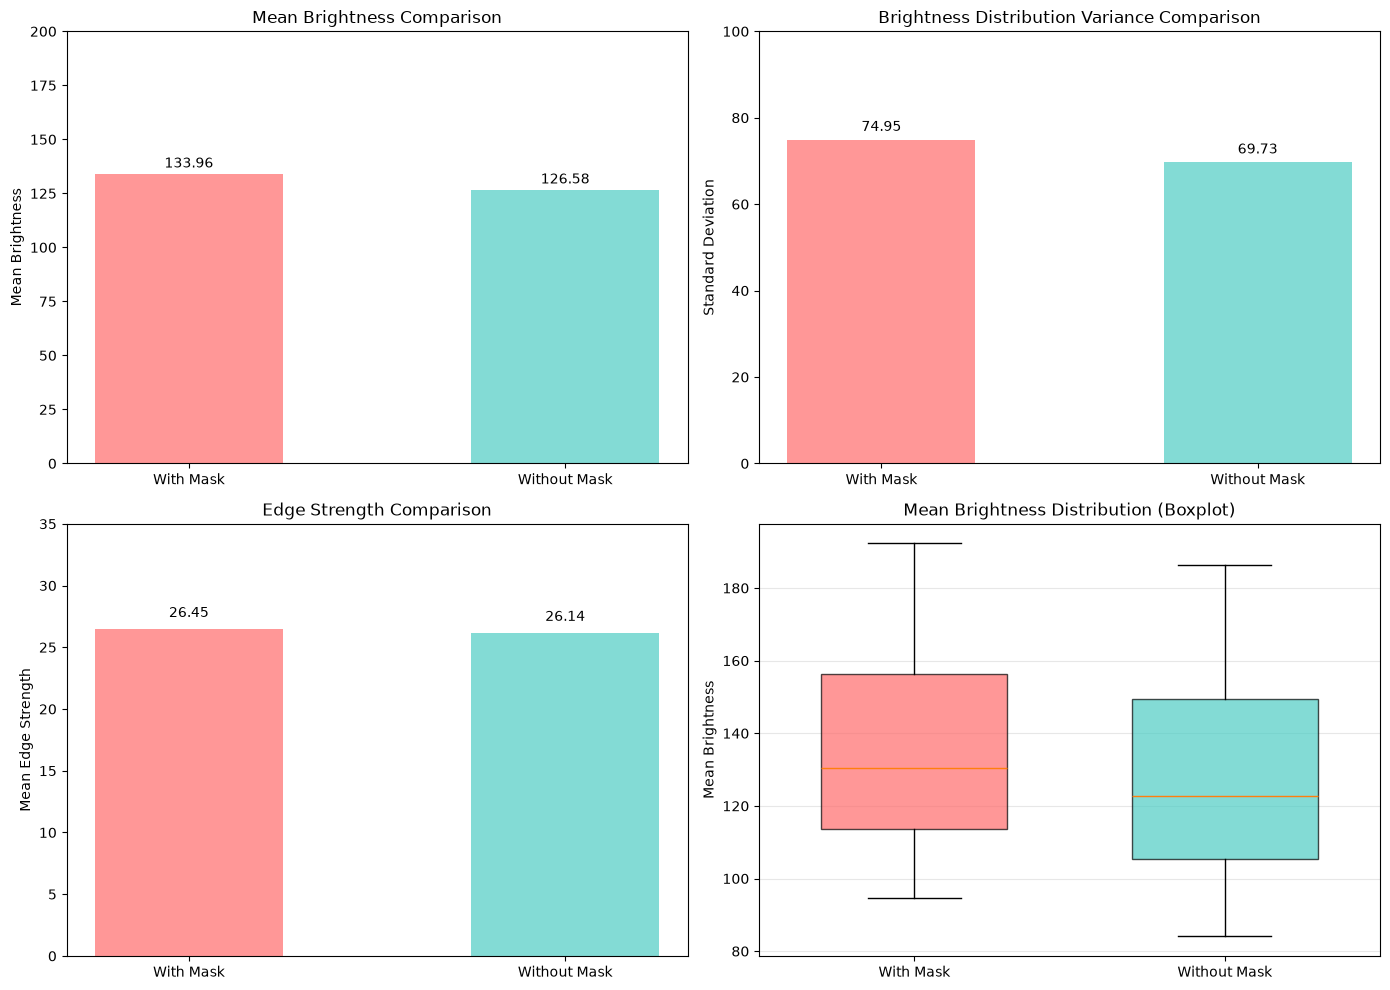


=== Detailed Statistical Analysis ===

Masked Images:
  - Mean Brightness: 133.96 ± 30.12
  - Standard Deviation: 74.95 ± 6.98
  - Edge Strength: 26.45 ± 4.83

Unmasked Images:
  - Mean Brightness: 126.58 ± 29.03
  - Standard Deviation: 69.73 ± 7.72
  - Edge Strength: 26.14 ± 4.95

Interpretation:
  - Masked images are approximately 5.83% brighter
  - Edge characteristics show minimal difference (1.19%)


In [8]:
# Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Mean brightness comparison
axes[0, 0].bar(['With Mask', 'Without Mask'], 
               [df_masked['mean'].mean(), df_unmasked['mean'].mean()],
               color=['#FF6B6B', '#4ECDC4'], alpha=0.7, width=0.5)
axes[0, 0].set_ylabel('Mean Brightness')
axes[0, 0].set_title('Mean Brightness Comparison')
axes[0, 0].set_ylim(0, 200)
for i, v in enumerate([df_masked['mean'].mean(), df_unmasked['mean'].mean()]):
    axes[0, 0].text(i, v + 3, f'{v:.2f}', ha='center')

# 2. Standard deviation comparison
axes[0, 1].bar(['With Mask', 'Without Mask'], 
               [df_masked['std'].mean(), df_unmasked['std'].mean()],
               color=['#FF6B6B', '#4ECDC4'], alpha=0.7, width=0.5)
axes[0, 1].set_ylabel('Standard Deviation')
axes[0, 1].set_title('Brightness Distribution Variance Comparison')
axes[0, 1].set_ylim(0, 100)
for i, v in enumerate([df_masked['std'].mean(), df_unmasked['std'].mean()]):
    axes[0, 1].text(i, v + 2, f'{v:.2f}', ha='center')

# 3. Edge mean comparison
axes[1, 0].bar(['With Mask', 'Without Mask'], 
               [df_masked['edge_mean'].mean(), df_unmasked['edge_mean'].mean()],
               color=['#FF6B6B', '#4ECDC4'], alpha=0.7, width=0.5)
axes[1, 0].set_ylabel('Mean Edge Strength')
axes[1, 0].set_title('Edge Strength Comparison')
axes[1, 0].set_ylim(0, 35)
for i, v in enumerate([df_masked['edge_mean'].mean(), df_unmasked['edge_mean'].mean()]):
    axes[1, 0].text(i, v + 1, f'{v:.2f}', ha='center')

# 4. Boxplot (mean brightness)
box_data = [df_masked['mean'].values, df_unmasked['mean'].values]
bp = axes[1, 1].boxplot(box_data, patch_artist=True, widths=0.6)
axes[1, 1].set_xticklabels(['With Mask', 'Without Mask'])
for patch, color in zip(bp['boxes'], ['#FF6B6B', '#4ECDC4']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1, 1].set_ylabel('Mean Brightness')
axes[1, 1].set_title('Mean Brightness Distribution (Boxplot)')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== Detailed Statistical Analysis ===")
print(f"\nMasked Images:")
print(f"  - Mean Brightness: {df_masked['mean'].mean():.2f} ± {df_masked['mean'].std():.2f}")
print(f"  - Standard Deviation: {df_masked['std'].mean():.2f} ± {df_masked['std'].std():.2f}")
print(f"  - Edge Strength: {df_masked['edge_mean'].mean():.2f} ± {df_masked['edge_mean'].std():.2f}")

print(f"\nUnmasked Images:")
print(f"  - Mean Brightness: {df_unmasked['mean'].mean():.2f} ± {df_unmasked['mean'].std():.2f}")
print(f"  - Standard Deviation: {df_unmasked['std'].mean():.2f} ± {df_unmasked['std'].std():.2f}")
print(f"  - Edge Strength: {df_unmasked['edge_mean'].mean():.2f} ± {df_unmasked['edge_mean'].std():.2f}")

print(f"\nInterpretation:")
print(f"  - Masked images are approximately {comparison.loc['mean', 'difference_pct']:.2f}% brighter")
print(f"  - Edge characteristics show minimal difference ({comparison.loc['edge_mean', 'difference_pct']:.2f}%)")

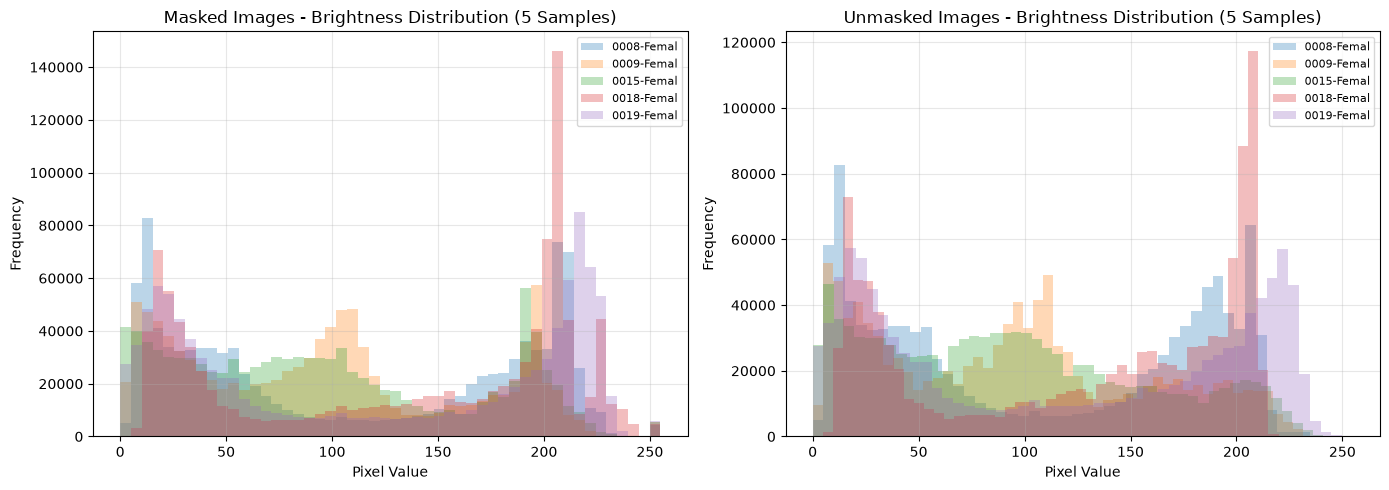


=== Detailed Statistics for All 20 Files ===
          filename  with_mask_mean  without_mask_mean  brightness_diff  with_mask_edge  without_mask_edge  brightness_diff_pct
0008-Female-27.png      110.849821         107.299004         3.550817       32.630992          31.867403                 3.31
0009-Female-21.png       96.119318          93.592097         2.527221       28.360879          28.470858                 2.70
0015-Female-25.png       97.821117          93.740884         4.080233       30.154491          30.604663                 4.35
0018-Female-29.png      133.745229         126.397943         7.347287       24.841642          24.030593                 5.81
0019-Female-30.png      121.619334         116.572947         5.046388       38.406450          38.799540                 4.33
0020-Female-22.png      128.971111         124.681186         4.289925       27.968168          27.157582                 3.44
0022-Female-27.png      154.036228         147.680649         6.3

In [9]:
# Histogram comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Masked images histogram
for filename in df_masked['filename'].values[:5]:
    masked_filename = filename.replace('.png', '_surgical.png')
    img = Image.open(os.path.join(dir2, masked_filename))
    img_gray = np.array(img.convert('L'))
    axes[0].hist(img_gray.flatten(), bins=50, alpha=0.3, label=filename[:10])

axes[0].set_xlabel('Pixel Value')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Masked Images - Brightness Distribution (5 Samples)')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Unmasked images histogram
for filename in df_unmasked['filename'].values[:5]:
    img = Image.open(os.path.join(dir1, filename))
    img_gray = np.array(img.convert('L'))
    axes[1].hist(img_gray.flatten(), bins=50, alpha=0.3, label=filename[:10])

axes[1].set_xlabel('Pixel Value')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Unmasked Images - Brightness Distribution (5 Samples)')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print combined dataframe
print("\n=== Detailed Statistics for All 20 Files ===")
combined_df = pd.DataFrame({
    'filename': df_masked['filename'].values,
    'with_mask_mean': df_masked['mean'].values,
    'without_mask_mean': df_unmasked['mean'].values,
    'brightness_diff': (df_masked['mean'].values - df_unmasked['mean'].values),
    'with_mask_edge': df_masked['edge_mean'].values,
    'without_mask_edge': df_unmasked['edge_mean'].values,
})
combined_df['brightness_diff_pct'] = (combined_df['brightness_diff'] / combined_df['without_mask_mean'] * 100).round(2)
print(combined_df.to_string(index=False))